In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from utilz.plotting_utilz import * 

In [3]:
results_dir = "../adv_results/vit_origins2/"
figures_dir = "./paper_figs_v3/"

In [4]:
METRIC = 'robust_top5'
RENORM = True
ATTACK_TYPE = 'pgd20'
MODEL_NAME = 'vit_b_16'

In [5]:
compressed_robust_accs = {}
null_compressed_robust_accs = {}
baseline_robust_acc = None
rank_fracs = None
layer_inds = None
projs_to_plot = proj_types + ['random']
random_seed_std = None
random_null_seed_std = None
# clean_accs = extract_layer_rank_grid(results_df, renorm=False, null_proj=False, topk=TOPK, acc_type='clean')
# robust_top5_null_renorm
for proj in projs_to_plot:
    if proj != 'random':
          results_df = pd.read_csv(f"{results_dir}/{proj}_{ATTACK_TYPE}.csv", index_col=0)
          compressed_robust_accs[proj] = extract_layer_rank_grid(results_df, renorm=RENORM, null_proj=False, metric=METRIC)
          if baseline_robust_acc is None:
               baseline_robust_acc = results_df.iloc[0][f'robust_baseline_{METRIC.split("_")[1]}']
               layer_inds = extract_layer_inds_from_data(results_df)
               rank_fracs = extract_rank_fracs_from_data(results_df)
          null_compressed_robust_accs[proj] = extract_layer_rank_grid(results_df, renorm=RENORM, null_proj=True, metric=METRIC)

    else:
          random_proj_robust_accs = []
          random_null_proj_robust_accs = []

          for rep_i in range(3):
               results_df = pd.read_csv(f"{results_dir}/random_seed{rep_i}_{ATTACK_TYPE}.csv", index_col=0)
               random_proj_robust_accs.append(extract_layer_rank_grid(results_df, renorm=RENORM, null_proj=False, metric=METRIC))
          random_null_proj_robust_accs.append(extract_layer_rank_grid(results_df, renorm=RENORM, null_proj=True, metric=METRIC))
          
          print(np.array(random_proj_robust_accs).shape)
          compressed_robust_accs['random'] = np.mean(random_proj_robust_accs, axis=0)
          random_seed_std = np.std(random_proj_robust_accs, axis=0)
          
          null_compressed_robust_accs['random'] = np.mean(random_null_proj_robust_accs, axis=0)
          random_null_seed_std = np.std(random_null_proj_robust_accs, axis=0)

(3, 12, 9)


In [6]:
print(compressed_robust_accs.keys(), [acc.shape for acc in compressed_robust_accs.values()])
random_seed_std.shape

dict_keys(['task', 'pca', 'local', 'gt', 'random']) [(12, 9), (12, 9), (12, 9), (12, 9), (12, 9)]


(12, 9)

In [7]:
proj_to_title['task'] = 'Task Sensitive'


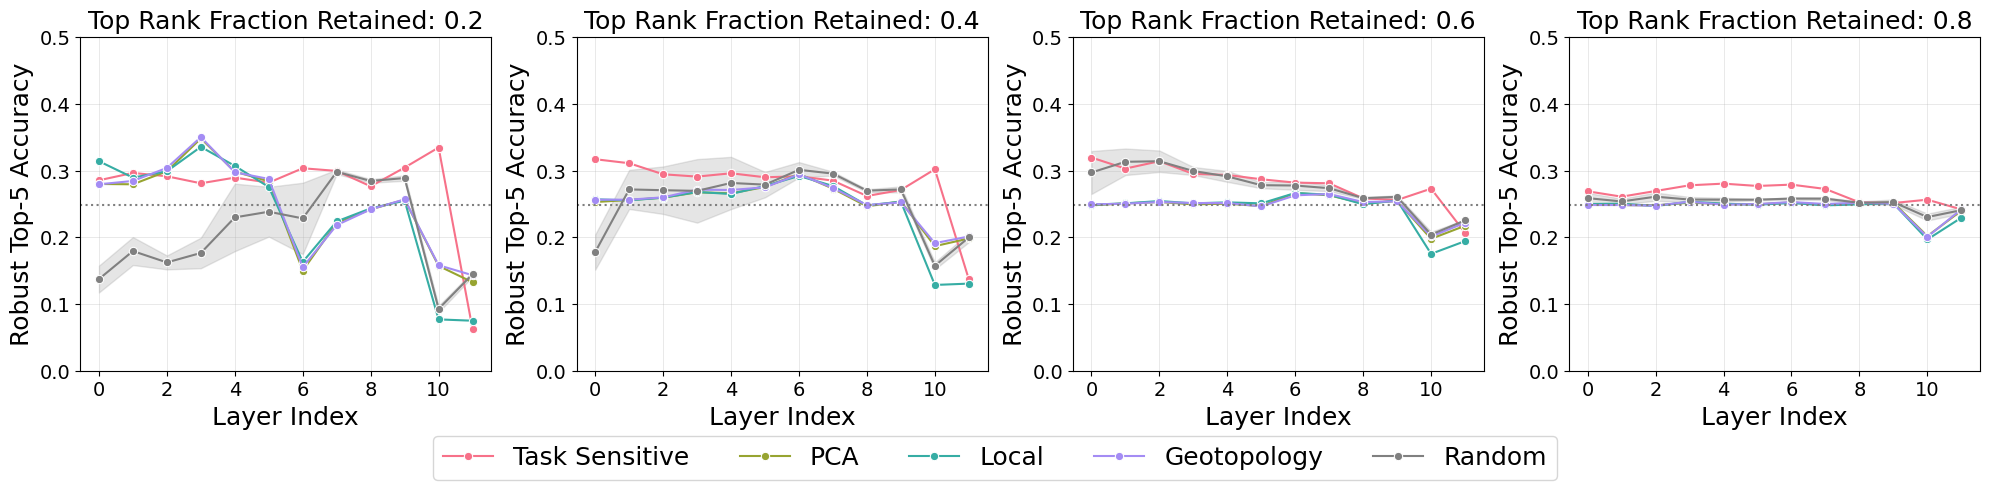

In [8]:

r_fracs_to_plot = [0.2, 0.4, 0.6, 0.8]

proj_to_title['random'] = 'Random'
proj_colors.append('grey')

fig, axes = plt.subplots(1, len(r_fracs_to_plot), figsize=(20, 5))
if 'top1' in METRIC:
    y_lim = (0, 0.2)
else:
    y_lim = (0, 0.5)

for i, r_frac in enumerate(r_fracs_to_plot):
    ax = axes[i]
    for ci, comp in enumerate(projs_to_plot):
        # find the column index corresponding to the rank fraction
        rank_col_index = np.where(rank_fracs == r_frac)[0][0]
        proj_adv_acc = compressed_robust_accs[comp][:, rank_col_index]
        null_proj_adv_acc = null_compressed_robust_accs[comp][:, rank_col_index]
        sns.lineplot(x=layer_inds, y=proj_adv_acc, label=f"{proj_to_title[comp]}", marker='o', ax=ax, color=proj_colors[ci])

        if comp == 'random':
            ax.fill_between(layer_inds, proj_adv_acc - random_seed_std[:, rank_col_index], proj_adv_acc + random_seed_std[:, rank_col_index], color=proj_colors[ci], alpha=0.2)

    ax.axhline(baseline_robust_acc, color='gray', linestyle=':')
    ax.set_title(f"Top Rank Fraction Retained: {r_frac}", fontsize=18)
    ax.set_xlabel("Layer Index", fontsize=18)
    ax.set_ylabel(f"{metric_to_title[METRIC]}", fontsize=18)
    ax.grid(True, which='both', linewidth=0.5, alpha=0.4)
    ax.tick_params(labelsize=14)
    ax.set_ylim(y_lim)
    # legend off
    ax.legend().remove()

    #

    

# add legend at the bottom of panel of all subplots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(projs_to_plot) + 1, fontsize=18)

# plt.suptitle(f"Adv Acc across Layers for Layerwise Projected Representations at Different Rank Fractions\nModel: {model_to_title[MODEL_NAME]}, Attack: {ATTACK_TYPE}")
plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.savefig(f"{figures_dir}/main/B1_layerwise_{METRIC}_lineplot.png", dpi=300)

## Fig B2 Global Fixed Allocation

In [4]:
def extract_global_rank_accs(df, renorm=False, null_proj=False, topk=5, acc_type='robust'):
    topk_str = f"top{topk}"
    proj_str = 'null_' if  null_proj else ''
    rep_str = 'renorm' if renorm else 'raw'
    acc_str = 'robust_' if acc_type == 'robust' else ''
    print(f"Extracting global accs for {proj_str} projection, renorm={renorm}, topk={topk}")
    col_format = f'{acc_str}{topk_str}_{proj_str}{rep_str}'
    cols = ['retain_fraction_total', col_format]
    
    # Filter the DataFrame to include only the relevant columns
    sub_df = df[cols].copy()

    # set rank as index and return the acc column as a series
    sub_df = sub_df.set_index('retain_fraction_total')
    return sub_df[col_format]



In [5]:
compressed_robust_accs = {}
null_compressed_robust_accs = {}

TOPK = 5

# comp_types = ['task', 'pca', 'local', 'gt']

for proj in proj_types_with_random:
    if proj != 'random':
        results_df = pd.read_csv(f"{results_dir}/{proj}_{ATTACK_TYPE}_global.csv", index_col=0)
        compressed_robust_accs[proj] = extract_global_rank_accs(results_df, renorm=RENORM, null_proj=False, topk=TOPK, acc_type='robust')
    
    else:
        random_proj_robust_accs = []
        for rep_i in range(3):
            results_df = pd.read_csv(f"{results_dir}/random_seed{rep_i}_{ATTACK_TYPE}_global.csv", index_col=0)
            random_proj_robust_accs.append(extract_global_rank_accs(results_df, renorm=RENORM, null_proj=False, topk=TOPK, acc_type='robust'))
        compressed_robust_accs['random'] = np.mean(random_proj_robust_accs, axis=0)
        random_seed_std = np.std(random_proj_robust_accs, axis=0)

        
baseline_robust_acc = results_df.iloc[0][f'robust_baseline_top{TOPK}']
rank_fracs = results_df['retain_fraction_total'].unique().round(1)

Extracting global accs for  projection, renorm=True, topk=5
Extracting global accs for  projection, renorm=True, topk=5
Extracting global accs for  projection, renorm=True, topk=5
Extracting global accs for  projection, renorm=True, topk=5
Extracting global accs for  projection, renorm=True, topk=5
Extracting global accs for  projection, renorm=True, topk=5
Extracting global accs for  projection, renorm=True, topk=5


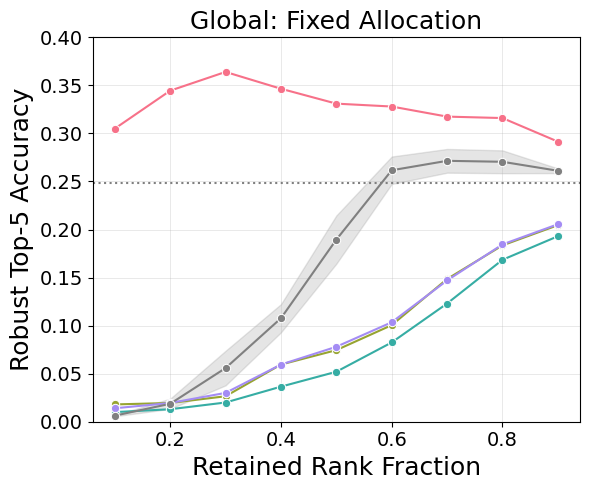

In [23]:
# fig 5 - line plot for adversarial accuracy across each rank frac


fig, ax = plt.subplots(1, 1, figsize=(6, 5))
y_lim = (0, 0.4)
proj_colors_to_plot = proj_colors + ['grey']


for ci, comp in enumerate(proj_types_with_random):
    # find the column index corresponding to the rank fraction

    if comp != 'random':
        proj_adv_acc = compressed_robust_accs[comp]
        sns.lineplot(x=rank_fracs, y=proj_adv_acc, label=f"{proj_to_title[comp]}", marker='o', ax=ax, color=proj_colors_to_plot[ci])
    else:
        proj_adv_acc = compressed_robust_accs[comp]
        sns.lineplot(x=rank_fracs, y=proj_adv_acc, label=f"{proj_to_title[comp]}", marker='o', ax=ax, color=proj_colors_to_plot[ci])
        ax.fill_between(rank_fracs, proj_adv_acc - random_seed_std, proj_adv_acc + random_seed_std, color=proj_colors_to_plot[ci], alpha=0.2)

    ax.set_xlabel("Retained Rank Fraction", fontsize=18)
    ax.set_ylabel(f"{metric_to_title[METRIC]}", fontsize=18)
    ax.set_ylim(y_lim)
    ax.tick_params(labelsize=14)

ax.set_title(f"Global: Fixed Allocation", fontsize=18)
    
  
ax.legend().remove()
ax.grid(True, which='both', linewidth=0.5, alpha=0.4)
ax.axhline(baseline_robust_acc, color='gray', linestyle=':', label='Baseline Adv Acc')
# 
plt.tight_layout()

plt.savefig(f"{figures_dir}/main/B2_{MODEL_NAME}_{ATTACK_TYPE}_global_projected_adv_acc_lineplots.png", dpi=300)

## Fig B2 - Adv accs heatmap for each projection

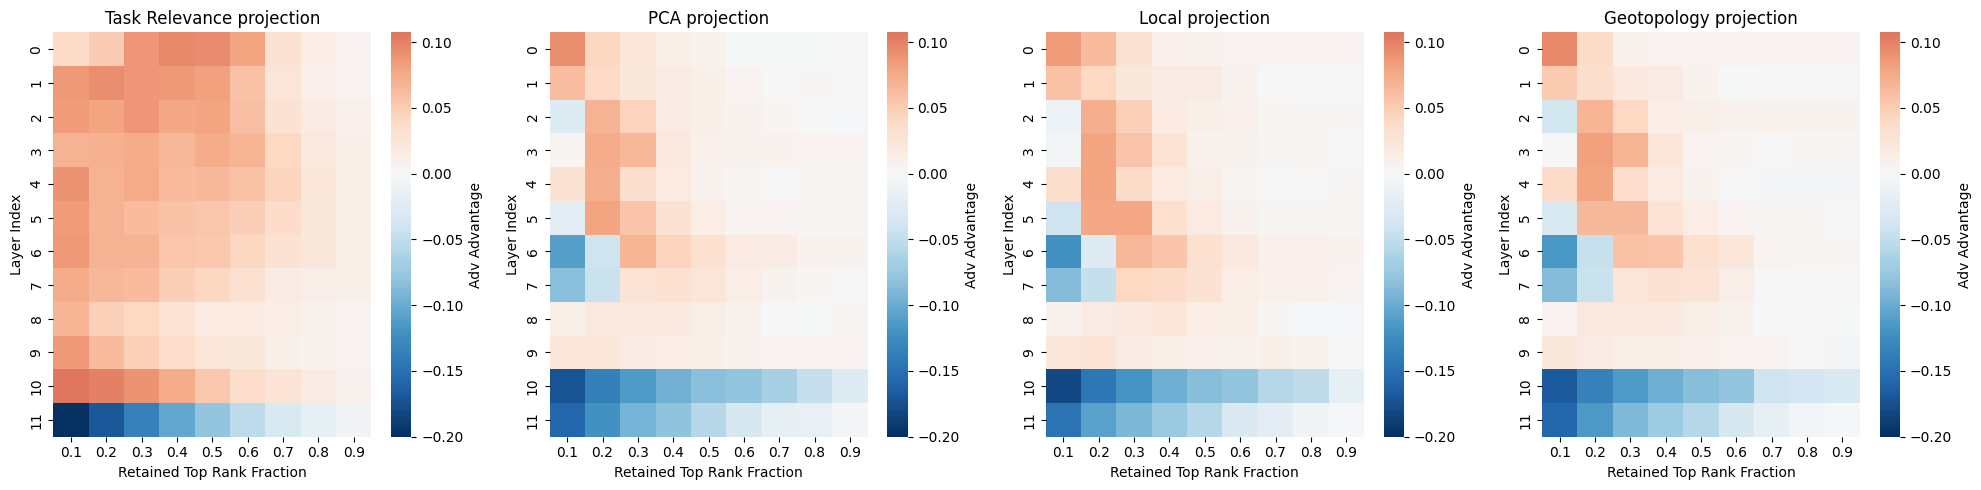

In [ ]:
fig, axes = plt.subplots(1, len(proj_types), figsize=(20, 5))
cmap_limits = (min(compressed_robust_accs[comp].min() - baseline_robust_acc for comp in proj_types), max(compressed_robust_accs[comp].max() - baseline_robust_acc for comp in proj_types))
for i, comp in enumerate(proj_types):
    baseline_adv_difference = compressed_robust_accs[comp] - baseline_robust_acc
    sns.heatmap(baseline_adv_difference, xticklabels=rank_fracs, yticklabels=layer_inds, ax=axes[i], 
            cmap='RdBu_r', cbar_kws={'label': f'Adv Advantage'}, center=0, vmin=cmap_limits[0], vmax=cmap_limits[1])
    axes[i].set_title(f"{proj_to_title[comp]} projection")
    axes[i].set_ylabel("Layer Index")
    axes[i].set_xlabel("Retained Top Rank Fraction")

# plt.suptitle(f"Adv Acc Advantage for Layerwise Projected Representations\nModel: {MODEL_NAME}, Attack: {ATTACK_TYPE}")
plt.tight_layout()
plt.savefig(f"{figures_dir}/main/B2_{MODEL_NAME}_{ATTACK_TYPE}_{METRIC}_heatmaps.png", dpi=300)

## Fig B3: Global 

## Fig SB 1 - heatmaps + random + null

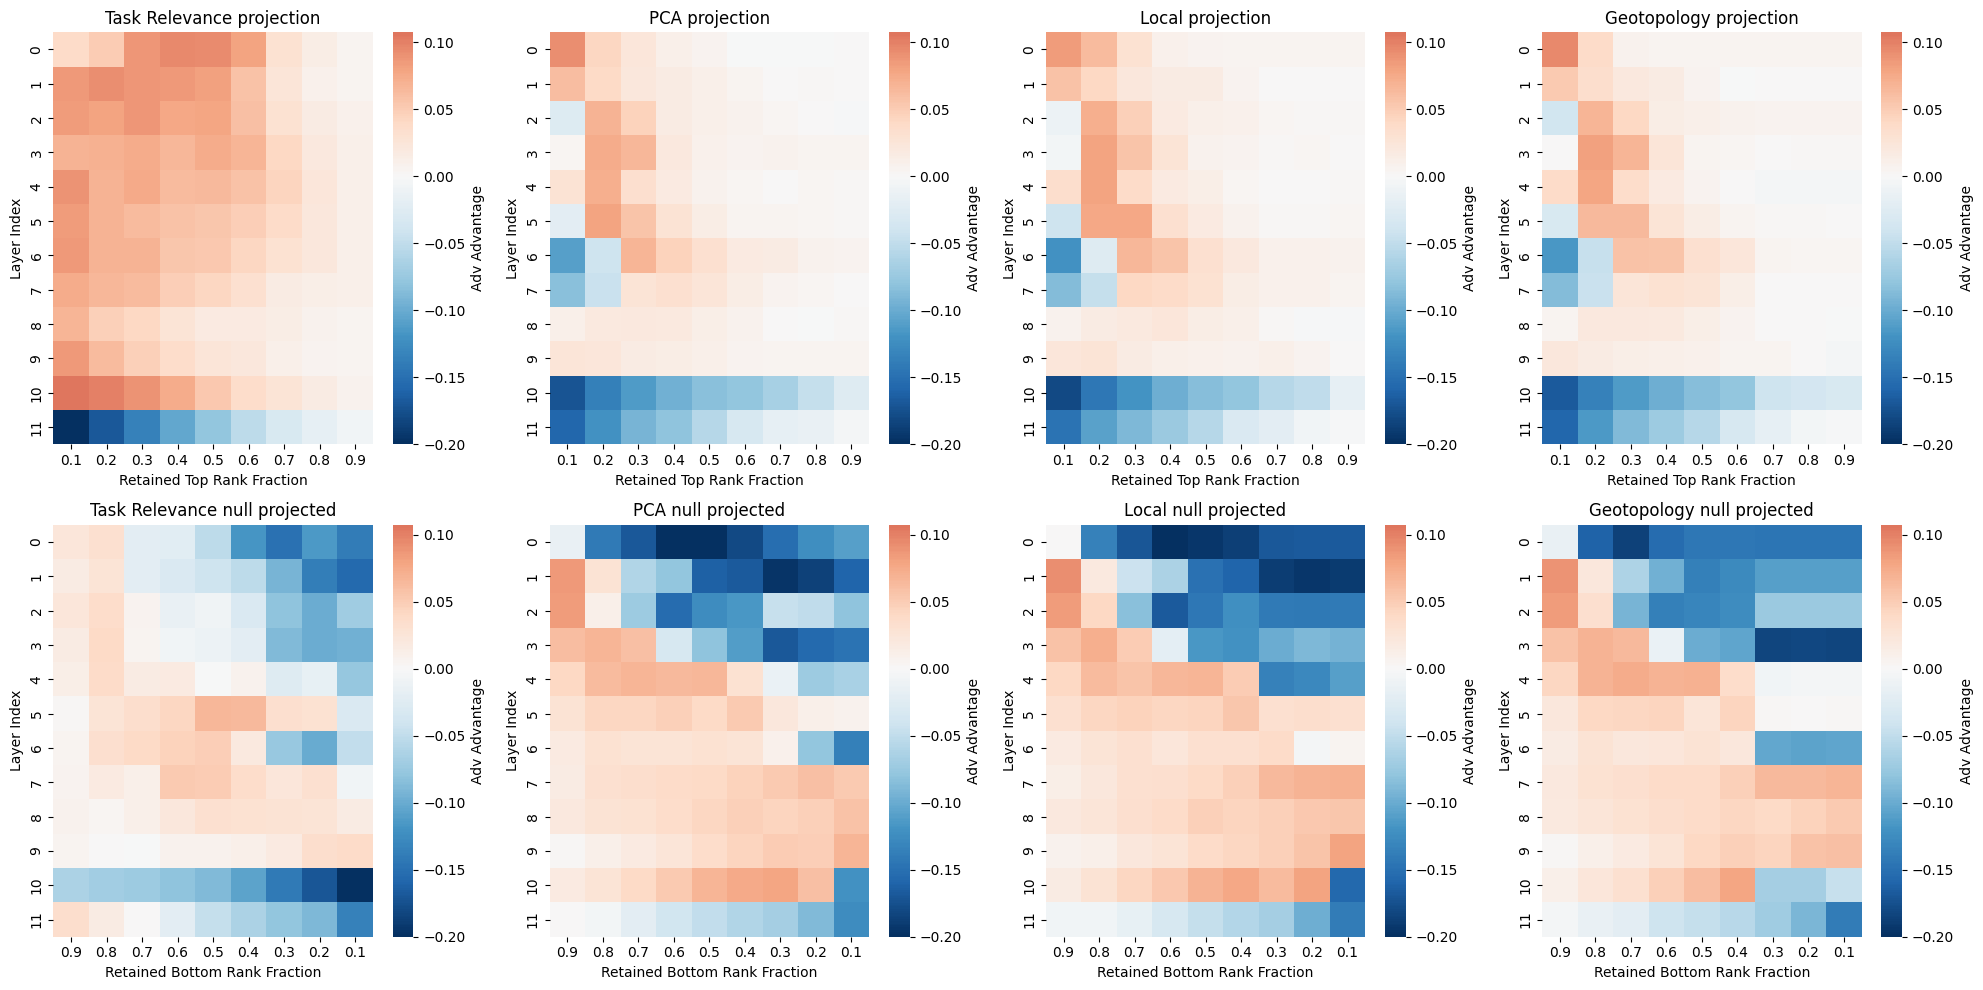

In [ ]:
fig, axes = plt.subplots(2, len(proj_types), figsize=(20, 10))
cmap_limits = (min(compressed_robust_accs[comp].min() - baseline_robust_acc for comp in proj_types), max(compressed_robust_accs[comp].max() - baseline_robust_acc for comp in proj_types))
for i, comp in enumerate(proj_types):
    baseline_adv_difference = compressed_robust_accs[comp] - baseline_robust_acc
    sns.heatmap(baseline_adv_difference, xticklabels=rank_fracs, yticklabels=layer_inds, ax=axes[0,i], 
            cmap='RdBu_r', cbar_kws={'label': f'Adv Advantage'}, center=0, vmin=cmap_limits[0], vmax=cmap_limits[1])
    axes[0,i].set_title(f"{proj_to_title[comp]} projection")
    axes[0,i].set_ylabel("Layer Index")
    axes[0,i].set_xlabel("Retained Top Rank Fraction")


    null_baseline_adv_difference = null_compressed_robust_accs[comp] - baseline_robust_acc
    null_rfracs = 1 - rank_fracs
    sns.heatmap(null_baseline_adv_difference, xticklabels=np.round(null_rfracs, 2), yticklabels=layer_inds, ax=axes[1,i], 
            cmap='RdBu_r', cbar_kws={'label': f'Adv Advantage'}, center=0, vmin=cmap_limits[0], vmax=cmap_limits[1])
    axes[1,i].set_title(f"{proj_to_title[comp]} null projected")
    axes[1,i].set_ylabel("Layer Index")
    axes[1,i].set_xlabel("Retained Bottom Rank Fraction")

# plt.suptitle(f"Adv Acc Advantage for Layerwise Projected Representations\nModel: {MODEL_NAME}, Attack: {ATTACK_TYPE}")
plt.tight_layout()
plt.savefig(f"{figures_dir}/supp/SB1_{MODEL_NAME}_{ATTACK_TYPE}_{METRIC}_heatmaps_null.png", dpi=300)